# Milestone 1 CIE – Retail Store Sales Analysis

## Project Overview

This project focuses on analyzing a Retail Store Sales dataset using Python and the Pandas library. The dataset contains retail transaction details, including customer information, product categories, prices, quantities, payment methods, locations, and transaction dates.

## Objectives

- Load and understand the retail sales dataset.
- Explore rows, columns, data types, and statistical information.
- Identify and handle missing values.
- Perform data cleaning and transformation.
- Analyze sales patterns and customer purchasing trends.
- Generate meaningful insights from the dataset.
- Create visualizations to present the findings.

## Tools and Technologies

- Python
- Google Colab
- Pandas
- NumPy
- Matplotlib
- Seaborn

## Dataset Information

**Dataset name:** Retail Store Sales – Dirty

**File name:** `retail_store_sales.csv`

**Number of rows:** 12,575

**Number of columns:** 11

## Expected Outcome

The project aims to clean, explore, and analyze retail sales data to identify useful business insights and present the findings through visualizations.

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


Load the retail store sales CSV file into a Pandas DataFrame.

In [ ]:
import os

print(os.listdir('/content'))

['.config', 'retail_store_sales.csv', 'sample_data']


In [ ]:
df = pd.read_csv('/content/retail_store_sales.csv')

df.head()

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,NaN
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


Check the number of rows and columns in the dataset.

In [ ]:
df.shape

(12575, 11)

Display all column names in the dataset.

In [ ]:
df.columns

Index(['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit',
       'Quantity', 'Total Spent', 'Payment Method', 'Location',
       'Transaction Date', 'Discount Applied'],
      dtype='object')

Check the data types and non-null values of each column.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12575 entries, 0 to 12574
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    12575 non-null  object 
 1   Customer ID       12575 non-null  object 
 2   Category          12575 non-null  object 
 3   Item              11362 non-null  object 
 4   Price Per Unit    11966 non-null  float64
 5   Quantity          11971 non-null  float64
 6   Total Spent       11971 non-null  float64
 7   Payment Method    12575 non-null  object 
 8   Location          12575 non-null  object 
 9   Transaction Date  12575 non-null  object 
 10  Discount Applied  8376 non-null   object 
dtypes: float64(3), object(8)
memory usage: 1.1+ MB


Display the statistical summary of numerical columns.

In [ ]:
df.describe()

,Price Per Unit,Quantity,Total Spent
count,11966.000000,11971.000000,11971.000000
mean,23.365912,5.536380,129.652577
std,10.743519,2.857883,94.750697
min,5.000000,1.000000,5.000000
25%,14.000000,3.000000,51.000000
50%,23.000000,6.000000,108.500000
75%,33.500000,8.000000,192.000000
max,41.000000,10.000000,410.000000


Identify the missing values in each column.

In [ ]:
df.isnull().sum()

,0
Transaction ID,0
Customer ID,0
Category,0
Item,1213
Price Per Unit,609
Quantity,604
Total Spent,604
Payment Method,0
Location,0
Transaction Date,0


Check whether the dataset contains duplicate rows.

In [ ]:
df.duplicated().sum()

np.int64(0)

Handle missing values by filling numerical columns with their mean values.

In [ ]:

df['Price Per Unit'] = df['Price Per Unit'].fillna(df['Price Per Unit'].mean())

df['Quantity'] = df['Quantity'].fillna(df['Quantity'].mean())

df['Total Spent'] = df['Total Spent'].fillna(df['Total Spent'].mean())

print("Missing numerical values handled successfully!")

Missing numerical values handled successfully!


Fill missing categorical values with the most frequent value.

In [ ]:
df['Item'] = df['Item'].fillna(df['Item'].mode()[0])

df['Discount Applied'] = df['Discount Applied'].fillna(df['Discount Applied'].mode()[0])

print("Missing categorical values handled successfully!")

Missing categorical values handled successfully!


/tmp/ipykernel_1357/3815831291.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Discount Applied'] = df['Discount Applied'].fillna(df['Discount Applied'].mode()[0])


Check whether any missing values remain after data cleaning.

In [ ]:
df.isnull().sum()

,0
Transaction ID,0
Customer ID,0
Category,0
Item,0
Price Per Unit,0
Quantity,0
Total Spent,0
Payment Method,0
Location,0
Transaction Date,0


Convert the Transaction Date column into datetime format.

In [ ]:
df['Transaction Date'] = pd.to_datetime(df['Transaction Date'])

df['Transaction Date'].dtype

dtype('<M8[ns]')

Display the cleaned dataset to verify the changes.

In [ ]:
df.head()

,Transaction ID,Customer ID,Category,Item,Price Per Unit,Quantity,Total Spent,Payment Method,Location,Transaction Date,Discount Applied
0,TXN_6867343,CUST_09,Patisserie,Item_10_PAT,18.5,10.0,185.0,Digital Wallet,Online,2024-04-08,True
1,TXN_3731986,CUST_22,Milk Products,Item_17_MILK,29.0,9.0,261.0,Digital Wallet,Online,2023-07-23,True
2,TXN_9303719,CUST_02,Butchers,Item_12_BUT,21.5,2.0,43.0,Credit Card,Online,2022-10-05,False
3,TXN_9458126,CUST_06,Beverages,Item_16_BEV,27.5,9.0,247.5,Credit Card,Online,2022-05-07,True
4,TXN_4575373,CUST_05,Food,Item_6_FOOD,12.5,7.0,87.5,Digital Wallet,Online,2022-10-02,False


Calculate the total sales amount from all transactions.

In [ ]:
total_sales = df['Total Spent'].sum()

print("Total Sales:", total_sales)

Total Sales: 1630381.1565449839


Calculate the total sales for each product category.

In [ ]:
category_sales = df.groupby('Category')['Total Spent'].sum()

print(category_sales)

Category
Beverages                             206252.832971
Butchers                              217452.985548
Computers and electric accessories    201194.358742
Electric household essentials         213537.443280
Food                                  205313.858742
Furniture                             203867.070086
Milk Products                         189317.332971
Patisserie                            193445.274204
Name: Total Spent, dtype: float64


Analyze the number of transactions made using each payment method.

In [ ]:
payment_counts = df['Payment Method'].value_counts()

print(payment_counts)

Payment Method
Cash              4310
Digital Wallet    4144
Credit Card       4121
Name: count, dtype: int64


Visualize total sales for each product category using a bar chart.

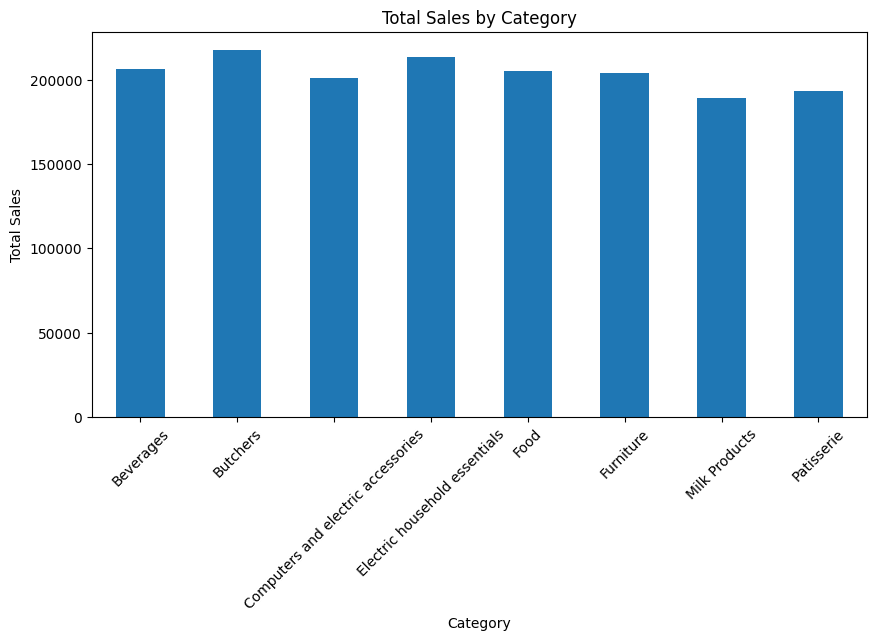

In [ ]:
category_sales.plot(kind='bar', figsize=(10, 5))

plt.title('Total Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

Visualize the usage of different payment methods using a pie chart.

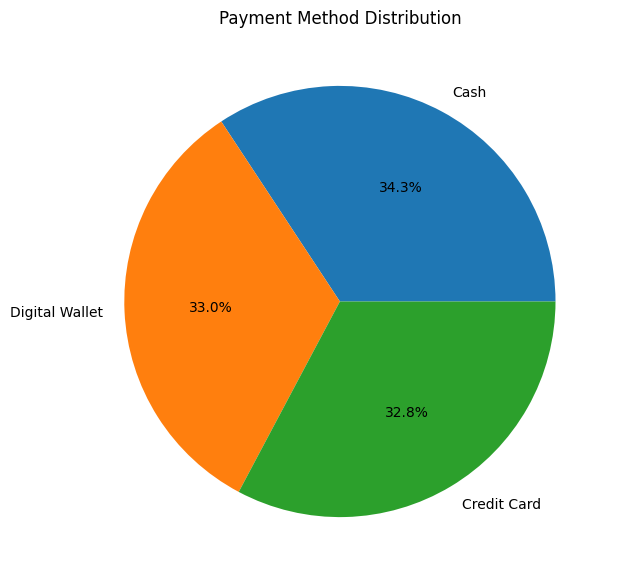

In [ ]:
payment_counts.plot(kind='pie', autopct='%1.1f%%', figsize=(7, 7))

plt.title('Payment Method Distribution')
plt.ylabel('')
plt.show()

Compare total sales between online and in-store transactions.

In [ ]:
location_sales = df.groupby('Location')['Total Spent'].sum()

print(location_sales)

Location
In-store    801899.519505
Online      828481.637040
Name: Total Spent, dtype: float64


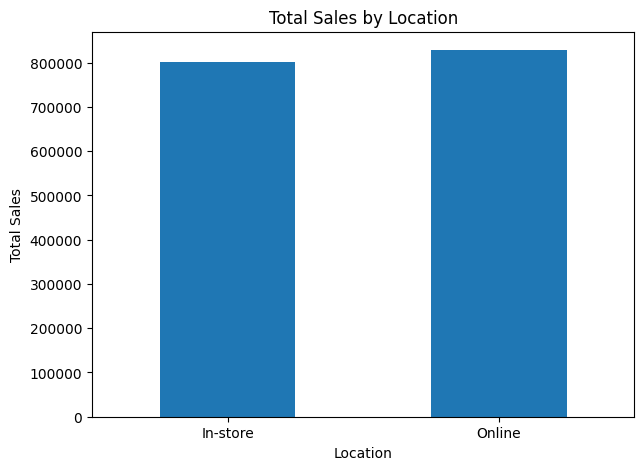

In [ ]:
location_sales.plot(kind='bar', figsize=(7, 5))

plt.title('Total Sales by Location')
plt.xlabel('Location')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.show()

Visualize the top 10 items based on total sales.

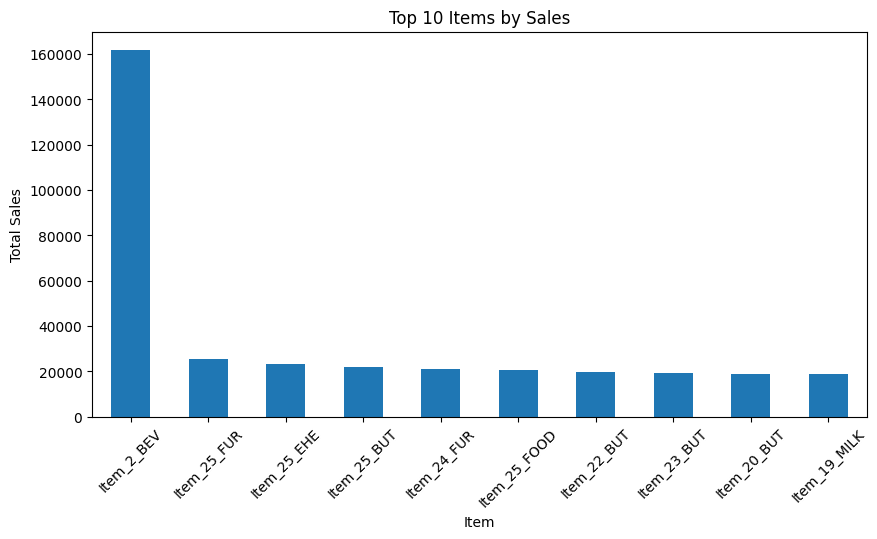

In [ ]:
item_sales = df.groupby('Item')['Total Spent'].sum().sort_values(ascending=False).head(10)

item_sales.plot(kind='bar', figsize=(10, 5))

plt.title('Top 10 Items by Sales')
plt.xlabel('Item')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.show()

Compare the quantity of products sold in each category.

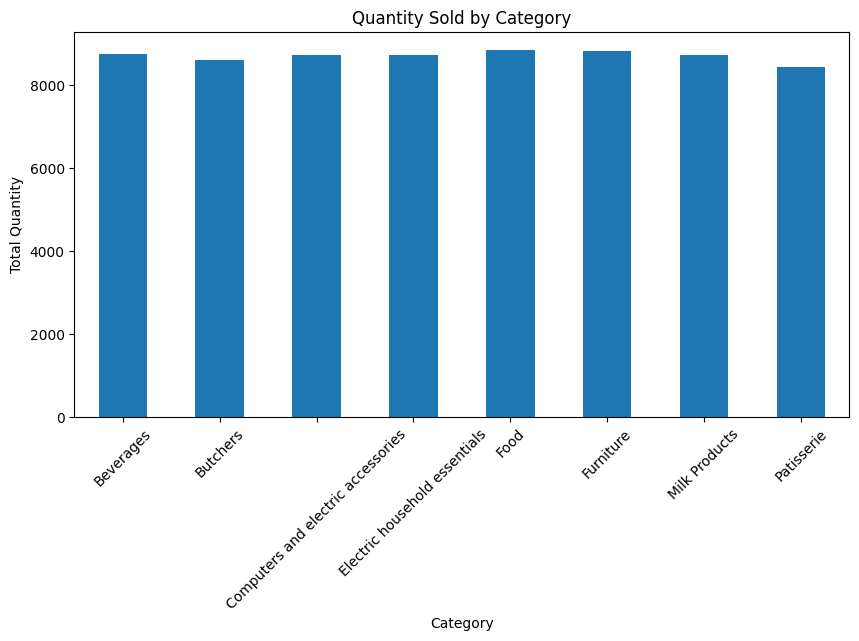

In [ ]:
quantity_by_category = df.groupby('Category')['Quantity'].sum()

quantity_by_category.plot(kind='bar', figsize=(10, 5))

plt.title('Quantity Sold by Category')
plt.xlabel('Category')
plt.ylabel('Total Quantity')
plt.xticks(rotation=45)
plt.show()

Analyze the spread of product prices using a box plot.

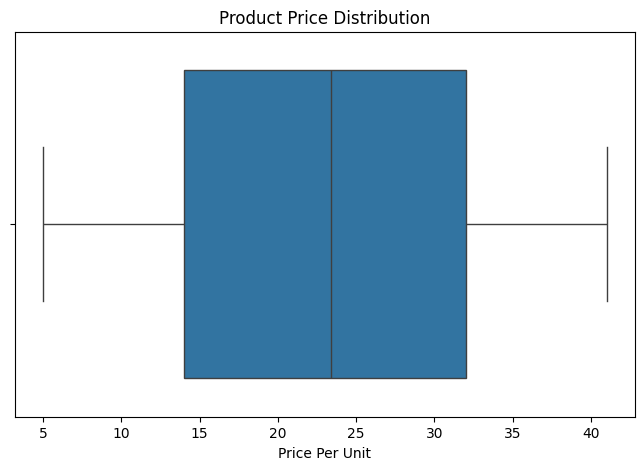

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(x=df['Price Per Unit'])

plt.title('Product Price Distribution')
plt.xlabel('Price Per Unit')
plt.show()

Study the relationship between quantity purchased and total amount spent.

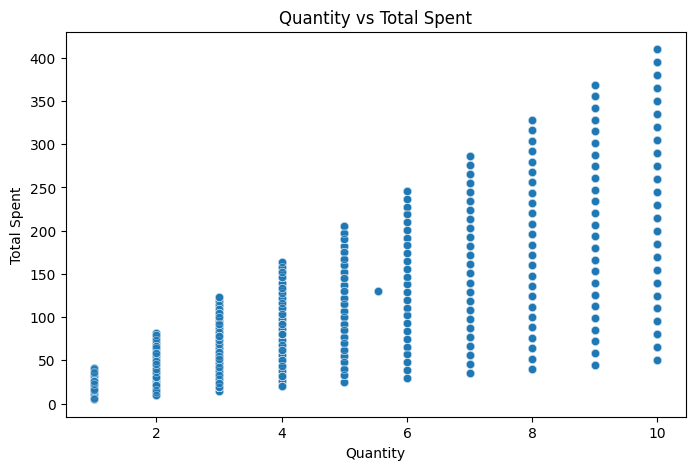

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Quantity', y='Total Spent', alpha=0.5)

plt.title('Quantity vs Total Spent')
plt.xlabel('Quantity')
plt.ylabel('Total Spent')
plt.show()

Visualize the correlation between numerical sales variables using a heatmap.

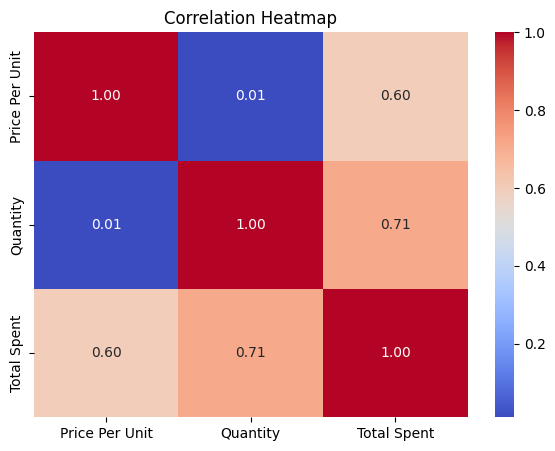

In [ ]:
plt.figure(figsize=(7, 5))

correlation = df[['Price Per Unit', 'Quantity', 'Total Spent']].corr()

sns.heatmap(correlation, annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Correlation Heatmap')
plt.show()

### Payment Method Distribution – Donut Chart

This donut chart shows the distribution of different payment methods used by customers. It helps identify the most commonly used payment method.

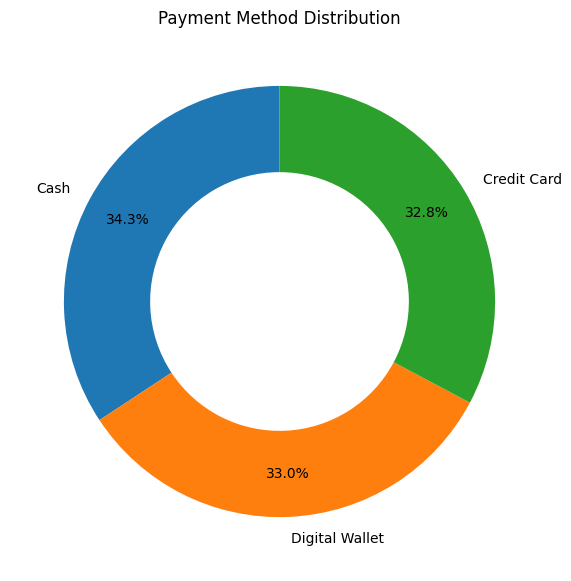

In [ ]:
plt.figure(figsize=(7, 7))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90,
    wedgeprops={'width': 0.4},
    pctdistance=0.8
)

plt.title('Payment Method Distribution')
plt.show()

Analyze the relationship between the quantity purchased and the total amount spent using a scatter plot.

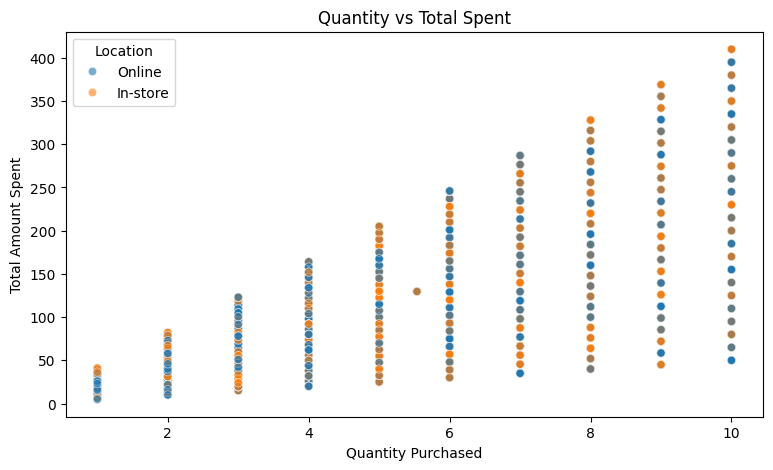

In [ ]:
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=df,
    x='Quantity',
    y='Total Spent',
    hue='Location',
    alpha=0.6
)

plt.title('Quantity vs Total Spent')
plt.xlabel('Quantity Purchased')
plt.ylabel('Total Amount Spent')
plt.legend(title='Location')
plt.show()

Visualize monthly sales trends over time using a line chart.

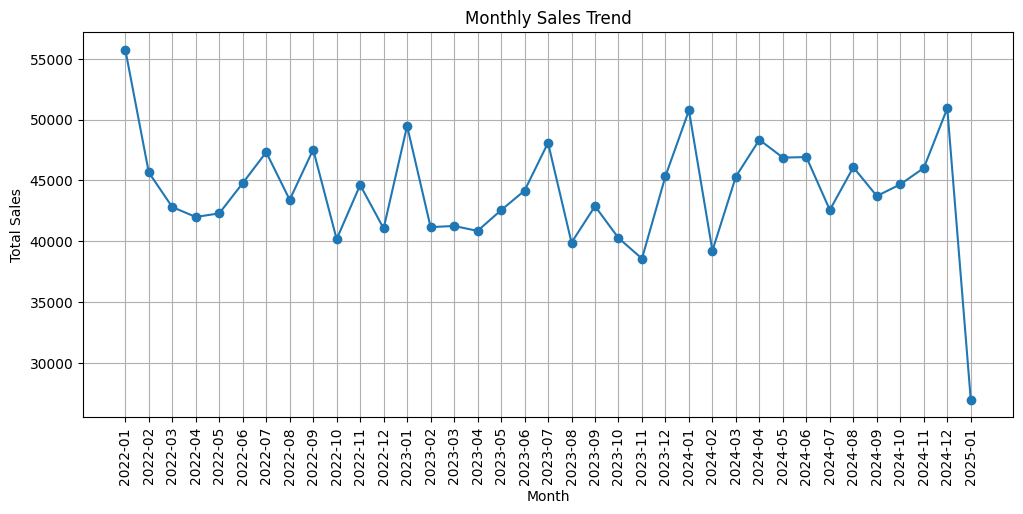

In [ ]:
monthly_sales = df.groupby(
    df['Transaction Date'].dt.to_period('M')
)['Total Spent'].sum()

monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

# Business Insights

The following insights were identified from the retail sales analysis.

In [ ]:
print("Total Sales:", round(total_sales, 2))

print("\nCategory with Highest Sales:")
print(category_sales.idxmax())

print("\nCategory with Lowest Sales:")
print(category_sales.idxmin())

print("\nMost Used Payment Method:")
print(payment_counts.idxmax())

print("\nSales by Location:")
print(location_sales)

Total Sales: 1630381.16

Category with Highest Sales:
Butchers

Category with Lowest Sales:
Milk Products

Most Used Payment Method:
Cash

Sales by Location:
Location
In-store    801899.519505
Online      828481.637040
Name: Total Spent, dtype: float64


## Interpretation of Business Insights

The analysis helps identify the highest and lowest sales categories.

It also shows the most frequently used payment method.

Sales by location help compare online and in-store transactions.

These insights help understand retail sales performance and customer purchasing behaviour.

# Conclusion

This project analyzed retail store sales data using Python, Pandas, Matplotlib, and Seaborn.

Data cleaning techniques were used to handle missing values and prepare the dataset for analysis.

Different visualizations helped understand category-wise sales, payment methods, purchasing patterns, and sales trends.

The analysis provided useful insights into retail sales performance and customer purchasing behavior.

This project improved my understanding of data analysis, data visualization, and business insights.

In [ ]:
df.to_csv('retail_store_sales_cleaned.csv', index=False)